# PulmoSight 09 — EfficientNet-B0 v2: Transfer Learning on Lung Crops, 3 Seeds

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


splits = pd.read_csv(ROOT / "splits" / "splits_lungcrop.csv")   # lung-cropped images (notebook 07)
train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df = splits[splits.split == "val"].reset_index(drop=True)
test_df = splits[splits.split == "test"].reset_index(drop=True)
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASSES))))

label  normal    tb
split              
test      861   820
train    6860  6585
val       850   809


In [3]:
import copy

# ---------------- Augmentation v2 (all on the GPU) ----------------
def _u(b, lo, hi, dev):
    return torch.empty(b, device=dev).uniform_(lo, hi)

def gaussian_blur(x, sigma, k=13):
    """Separable Gaussian blur with a per-image sigma [B] (max 2.0 -> 13 taps).
    The kernel size and batch shape are FIXED on purpose: with cudnn.benchmark=True, every new conv shape
    triggers a fresh cuDNN autotune (~1 s), which made a variable-shape blur run at ~30 img/s."""
    r = torch.arange(k, device=x.device).float() - k // 2
    g = torch.exp(-r ** 2 / (2 * sigma.view(-1, 1) ** 2)); g = g / g.sum(1, keepdim=True)    # [B, k]
    B, (H, W) = x.size(0), x.shape[-2:]
    x = x.reshape(1, B, H, W)                                   # one depthwise conv over the whole batch
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), g.view(B, 1, 1, k), groups=B)
    x = F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), g.view(B, 1, k, 1), groups=B)
    return x.view(B, 1, H, W)

def gpu_augment_v2(x):
    """x: float [B,1,H,W] in [0,1]."""
    b, dev = x.size(0), x.device
    # 1) random resized crop (scale 0.80-1.00, aspect 0.9-1.1) + rotation +-10 deg, as one affine warp
    area, aspect = _u(b, 0.80, 1.00, dev), torch.exp(_u(b, math.log(0.9), math.log(1.1), dev))
    sx, sy = torch.sqrt(area * aspect).clamp(max=1), torch.sqrt(area / aspect).clamp(max=1)
    tx, ty = (1 - sx) * _u(b, -1, 1, dev), (1 - sy) * _u(b, -1, 1, dev)
    ang = _u(b, -10, 10, dev) * math.pi / 180
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([torch.stack([cos * sx, -sin * sy, tx], 1), torch.stack([sin * sx, cos * sy, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), mode="bilinear", padding_mode="border", align_corners=False)
    # 2) brightness, contrast, gamma
    x = x * _u(b, 0.8, 1.2, dev).view(b, 1, 1, 1)
    m = x.mean((2, 3), keepdim=True)
    x = ((x - m) * _u(b, 0.8, 1.2, dev).view(b, 1, 1, 1) + m).clamp(1e-4, 1)
    x = x ** _u(b, 0.7, 1.4, dev).view(b, 1, 1, 1)
    # 3) blur (p=0.3) and low-resolution simulation (p=0.25)
    sel = (torch.rand(b, device=dev) < 0.3).view(b, 1, 1, 1)
    x = torch.where(sel, gaussian_blur(x, _u(b, 0.1, 2.0, dev)), x)
    sel = torch.rand(b, device=dev) < 0.25
    if sel.any():
        s = int(np.random.choice([128, 192, 256, 384]))
        x[sel] = F.interpolate(F.interpolate(x[sel], size=s, mode="area"), size=x.shape[-1], mode="bilinear", align_corners=False)
    # 4) Gaussian noise (p=0.5)
    sigma = _u(b, 0, 0.04, dev).view(b, 1, 1, 1) * (torch.rand(b, 1, 1, 1, device=dev) < 0.5)
    x = x + torch.randn_like(x) * sigma
    # 5) random erasing of one 5-20% patch (p=0.25), filled with the image mean
    H, W = x.shape[-2:]
    er_area, er_aspect = _u(b, 0.05, 0.20, dev), torch.exp(_u(b, math.log(0.5), math.log(2), dev))
    eh, ew = (torch.sqrt(er_area * er_aspect) * H).clamp(max=H), (torch.sqrt(er_area / er_aspect) * W).clamp(max=W)
    y0e, x0e = torch.rand(b, device=dev) * (H - eh), torch.rand(b, device=dev) * (W - ew)
    yy = torch.arange(H, device=dev).view(1, H, 1); xx = torch.arange(W, device=dev).view(1, 1, W)
    box = (yy >= y0e.view(b, 1, 1)) & (yy < (y0e + eh).view(b, 1, 1)) & (xx >= x0e.view(b, 1, 1)) & (xx < (x0e + ew).view(b, 1, 1))
    box = box & (torch.rand(b, 1, 1, device=dev) < 0.25)
    x = torch.where(box[:, None], x.mean((2, 3), keepdim=True), x)
    return x.clamp(0, 1)

def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment_v2(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


# ---------------- Exponential moving average of the weights ----------------
class EMA:
    """Keeps a slowly-moving average of the weights; usually generalises better than the raw weights."""
    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.steps = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        d = min(self.decay, (1 + self.steps) / (10 + self.steps))     # warm-up: follow the model closely at first
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            else:
                e.copy_(m)


def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")

@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with autocast():
            out = model(prepare_batch(x))
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()

def evaluate(model, loader):
    lg, y = predict_logits(model, loader)
    p = torch.from_numpy(lg).softmax(1)[:, 1].numpy(); pred = p >= 0.5
    return {"loss": F.cross_entropy(torch.from_numpy(lg), torch.from_numpy(y)).item(), "auroc": roc_auc_score(y, p),
            "acc": float((pred == y).mean()), "sens": float(pred[y == 1].mean()), "spec": float((~pred)[y == 0].mean())}

def warmup_cosine(optimizer, warmup_steps, total_steps):
    f = lambda s: (s + 1) / warmup_steps if s < warmup_steps else 0.5 * (1 + math.cos(math.pi * (s - warmup_steps) / max(1, total_steps - warmup_steps)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)


def fit_v2(model, optimizer, scheduler, cfg, run_dir, meta, accum_steps=1):
    """Train with EMA; every epoch score the EMA model on a clean (no-augmentation) train subset and on validation.
    Keep the EMA weights with the LOWEST validation loss; stop after `patience` epochs without improvement."""
    run_dir.mkdir(parents=True, exist_ok=True)
    train_loader = XrayLoader(train_df, cfg["batch_size"], shuffle=True, drop_last=True, seed=cfg["seed"])
    ema = EMA(model, cfg["ema_decay"])
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    history, best_loss, bad = [], float("inf"), 0
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time(); model.train()
        loss_sum = torch.zeros((), device=DEVICE); seen = 0
        optimizer.zero_grad(set_to_none=True)
        for i, (x, y) in enumerate(train_loader):
            x, y = prepare_batch(x, augment=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                out = model(x)
            loss = criterion(out.float(), y)
            (loss / accum_steps).backward()
            if (i + 1) % accum_steps == 0:
                nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                optimizer.step(); optimizer.zero_grad(set_to_none=True); scheduler.step(); ema.update(model)
            loss_sum += loss.detach() * y.size(0); seen += y.size(0)
        tr, va = evaluate(ema.module, clean_train_loader), evaluate(ema.module, val_loader)
        row = {"epoch": epoch, "train_loss_aug": loss_sum.item() / seen,
               **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in va.items()},
               "lr": optimizer.param_groups[-1]["lr"], "seconds": time.time() - t0}
        history.append(row)
        flag = ""
        if va["loss"] < best_loss - 1e-4:
            best_loss, bad, flag = va["loss"], 0, "  * best (saved)"
            torch.save({**meta, "state_dict": ema.module.state_dict(), "epoch": epoch, "val_metrics": va, "config": cfg}, run_dir / "best.pth")
        else:
            bad += 1
        print(f"Ep {epoch:02d} | aug-train loss {row['train_loss_aug']:.3f} | clean-train loss {tr['loss']:.3f} AUROC {tr['auroc']:.4f} | "
              f"val loss {va['loss']:.3f} AUROC {va['auroc']:.4f} acc {va['acc']:.3f} | gap {va['loss'] - tr['loss']:+.3f} | {row['seconds']:.0f}s{flag}")
        (run_dir / "history.json").write_text(json.dumps(history, indent=2))
        if bad >= cfg["patience"]:
            print(f"Early stopping: validation loss has not improved for {cfg['patience']} epochs."); break
    return history


def plot_history_v2(history, title):
    h = pd.DataFrame(history)
    best = h.loc[h.val_loss.idxmin()]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
    axes[0].plot(h.epoch, h.train_loss_aug, ":", color="gray", label="train (augmented, raw weights)")
    axes[0].plot(h.epoch, h.train_loss, "o-", ms=3, label="train (clean, EMA)")
    axes[0].plot(h.epoch, h.val_loss, "s-", ms=3, label="validation (EMA)")
    axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend(fontsize=8)
    axes[1].plot(h.epoch, h.val_loss - h.train_loss, "o-", ms=3, color="tab:red")
    axes[1].axhline(0, color="k", lw=0.6); axes[1].set(title="Generalisation gap (val − clean-train loss)", xlabel="epoch")
    axes[2].plot(h.epoch, h.train_auroc, "o-", ms=3, label="train (clean)"); axes[2].plot(h.epoch, h.val_auroc, "s-", ms=3, label="validation")
    axes[2].set(title="AUROC", xlabel="epoch"); axes[2].legend(fontsize=8)
    for ax in axes: ax.axvline(best.epoch, color="gray", ls="--", lw=0.8)
    fig.suptitle(f"{title} — kept epoch {int(best.epoch)} (lowest validation loss)", weight="bold"); fig.tight_layout()
    return fig

clean_train_loader = XrayLoader(train_df.sample(min(1600, len(train_df)), random_state=SEED).reset_index(drop=True), 64)
val_loader = XrayLoader(val_df, 64)

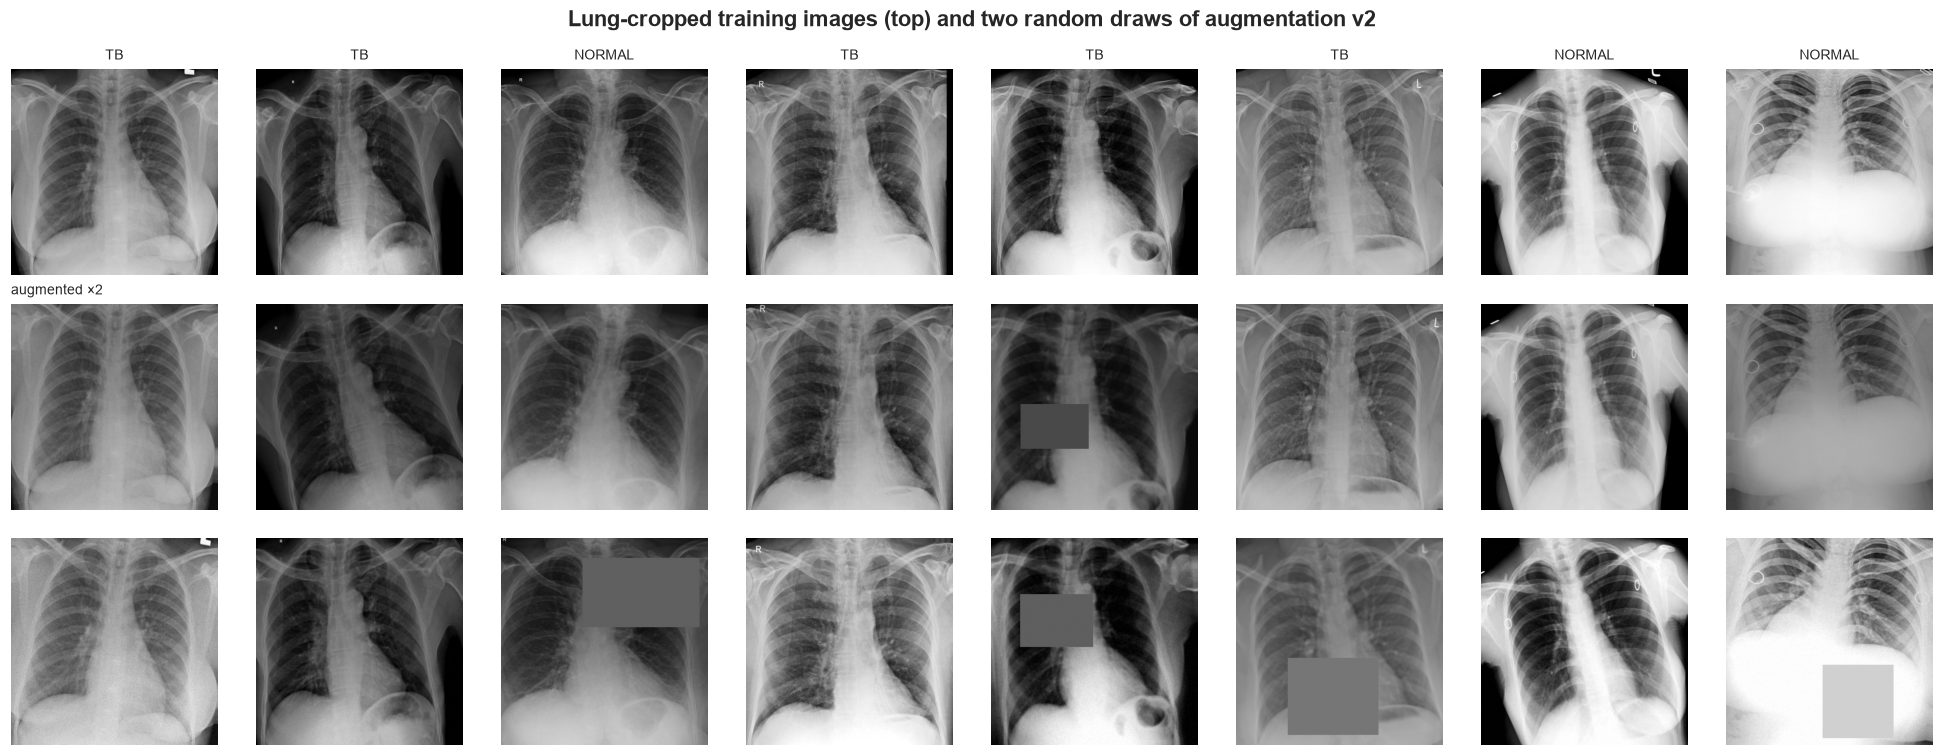

In [4]:
x, y = next(iter(XrayLoader(train_df, batch_size=8, shuffle=True)))
fig, axes = plt.subplots(3, 8, figsize=(18, 7))
for i in range(8):
    axes[0, i].imshow(x[i, 0], cmap="gray"); axes[0, i].set_title(CLASSES[y[i]].upper(), fontsize=9)
for r in (1, 2):
    aug = prepare_batch(x, augment=True).float().cpu() * STD + MEAN
    for i in range(8):
        axes[r, i].imshow(aug[i, 0].clamp(0, 1), cmap="gray", vmin=0, vmax=1)
for ax in axes.flat: ax.axis("off")
axes[1, 0].set_title("augmented ×2", fontsize=9, loc="left")
plt.suptitle("Lung-cropped training images (top) and two random draws of augmentation v2", weight="bold"); plt.tight_layout(); plt.show()

In [5]:
from torchvision import models

def build_efficientnet_b0(pretrained=True, drop=0.3, stochastic_depth=0.2):
    """ImageNet EfficientNet-B0 adapted to 1-channel X-rays (RGB stem filters summed)."""
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights, stochastic_depth_prob=stochastic_depth)
    stem = model.features[0][0]
    gray = nn.Conv2d(1, stem.out_channels, stem.kernel_size, stem.stride, stem.padding, bias=False)
    with torch.no_grad():
        gray.weight.copy_(stem.weight.sum(dim=1, keepdim=True))
    model.features[0][0] = gray
    model.classifier = nn.Sequential(nn.Dropout(drop), nn.Linear(1280, 2))
    return model

## Layer-wise learning rates

In [6]:
CONFIG = dict(arch="efficientnet_b0_v2", epochs=13, batch_size=16, accum_steps=2, backbone_lr=1e-4, layer_decay=0.7,
              head_lr=5e-4, weight_decay=0.05, warmup_epochs=1, label_smoothing=0.1, ema_decay=0.999, patience=4,
              dropout=0.4, stochastic_depth=0.3)

def param_groups(model):
    groups = []
    n = len(model.features)
    for i, stage in enumerate(model.features):
        lr = CONFIG["backbone_lr"] * CONFIG["layer_decay"] ** (n - 1 - i)
        ps = list(stage.parameters())
        groups += [{"params": [p for p in ps if p.ndim > 1], "lr": lr, "weight_decay": CONFIG["weight_decay"], "name": f"stage{i}"},
                   {"params": [p for p in ps if p.ndim <= 1], "lr": lr, "weight_decay": 0.0, "name": f"stage{i}-norm"}]
    head = list(model.classifier.parameters())
    groups += [{"params": [p for p in head if p.ndim > 1], "lr": CONFIG["head_lr"], "weight_decay": CONFIG["weight_decay"], "name": "head"},
               {"params": [p for p in head if p.ndim <= 1], "lr": CONFIG["head_lr"], "weight_decay": 0.0, "name": "head-bias"}]
    return groups

demo = build_efficientnet_b0(pretrained=True, drop=CONFIG["dropout"], stochastic_depth=CONFIG["stochastic_depth"])
lr_table = pd.DataFrame([{"group": g["name"], "parameters": sum(p.numel() for p in g["params"]), "peak LR": g["lr"]}
                         for g in param_groups(demo) if not g["name"].endswith(("norm", "bias"))])
display(lr_table.style.format({"parameters": "{:,}", "peak LR": "{:.2e}"}))
del demo

,group,parameters,peak LR
0,stage0,288,5.76e-06
1,stage1,"1,312",8.24e-06
2,stage2,"15,408",1.18e-05
3,stage3,"44,544",1.68e-05
4,stage4,"236,400",2.40e-05
5,stage5,"533,280",3.43e-05
6,stage6,"2,004,000",4.90e-05
7,stage7,"710,784",7.00e-05
8,stage8,"409,600",1.00e-04
9,head,"2,560",5.00e-04


## Train 3 seeds

In [7]:
SEEDS = [42, 7, 2024]
histories, minutes = {}, {}
for seed in SEEDS:
    print(f"\n================ seed {seed} ================")
    seed_everything(seed)
    model = build_efficientnet_b0(pretrained=True, drop=CONFIG["dropout"],
                                  stochastic_depth=CONFIG["stochastic_depth"]).to(DEVICE, memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(param_groups(model))
    steps = len(train_df) // CONFIG["batch_size"] // CONFIG["accum_steps"]
    scheduler = warmup_cosine(optimizer, CONFIG["warmup_epochs"] * steps, CONFIG["epochs"] * steps)
    meta = {"arch": "efficientnet_b0", "classes": CLASSES, "image_size": IMAGE_SIZE, "mean": MEAN, "std": STD,
            "input": "lungcrop512", "model_kwargs": {"drop": CONFIG["dropout"], "stochastic_depth": CONFIG["stochastic_depth"]}}
    t0 = time.time()
    histories[seed] = fit_v2(model, optimizer, scheduler, {**CONFIG, "seed": seed},
                             ROOT / "models" / "efficientnet_b0_v2" / f"seed{seed}", meta, accum_steps=CONFIG["accum_steps"])
    minutes[seed] = (time.time() - t0) / 60
    del model, optimizer; torch.cuda.empty_cache()


================ seed 42 ================


Ep 01 | aug-train loss 0.649 | clean-train loss 0.512 AUROC 0.8307 | val loss 0.511 AUROC 0.8316 acc 0.740 | gap -0.001 | 275s  * best (saved)


Ep 02 | aug-train loss 0.571 | clean-train loss 0.441 AUROC 0.8811 | val loss 0.462 AUROC 0.8659 acc 0.769 | gap +0.021 | 130s  * best (saved)


Ep 03 | aug-train loss 0.547 | clean-train loss 0.419 AUROC 0.8944 | val loss 0.441 AUROC 0.8809 acc 0.781 | gap +0.021 | 129s  * best (saved)


Ep 04 | aug-train loss 0.527 | clean-train loss 0.411 AUROC 0.9029 | val loss 0.435 AUROC 0.8897 acc 0.784 | gap +0.024 | 133s  * best (saved)


Ep 05 | aug-train loss 0.517 | clean-train loss 0.390 AUROC 0.9103 | val loss 0.420 AUROC 0.8944 acc 0.799 | gap +0.031 | 130s  * best (saved)


... (30 outputs left out)

Ep 10 | aug-train loss 0.480 | clean-train loss 0.357 AUROC 0.9288 | val loss 0.392 AUROC 0.9097 acc 0.808 | gap +0.035 | 135s  * best (saved)


Ep 11 | aug-train loss 0.474 | clean-train loss 0.353 AUROC 0.9301 | val loss 0.389 AUROC 0.9106 acc 0.812 | gap +0.036 | 135s  * best (saved)


Ep 12 | aug-train loss 0.474 | clean-train loss 0.350 AUROC 0.9311 | val loss 0.386 AUROC 0.9115 acc 0.815 | gap +0.037 | 128s  * best (saved)


Ep 13 | aug-train loss 0.475 | clean-train loss 0.347 AUROC 0.9314 | val loss 0.384 AUROC 0.9119 acc 0.814 | gap +0.037 | 127s  * best (saved)


## Learning curves (seed 42) and overfitting check

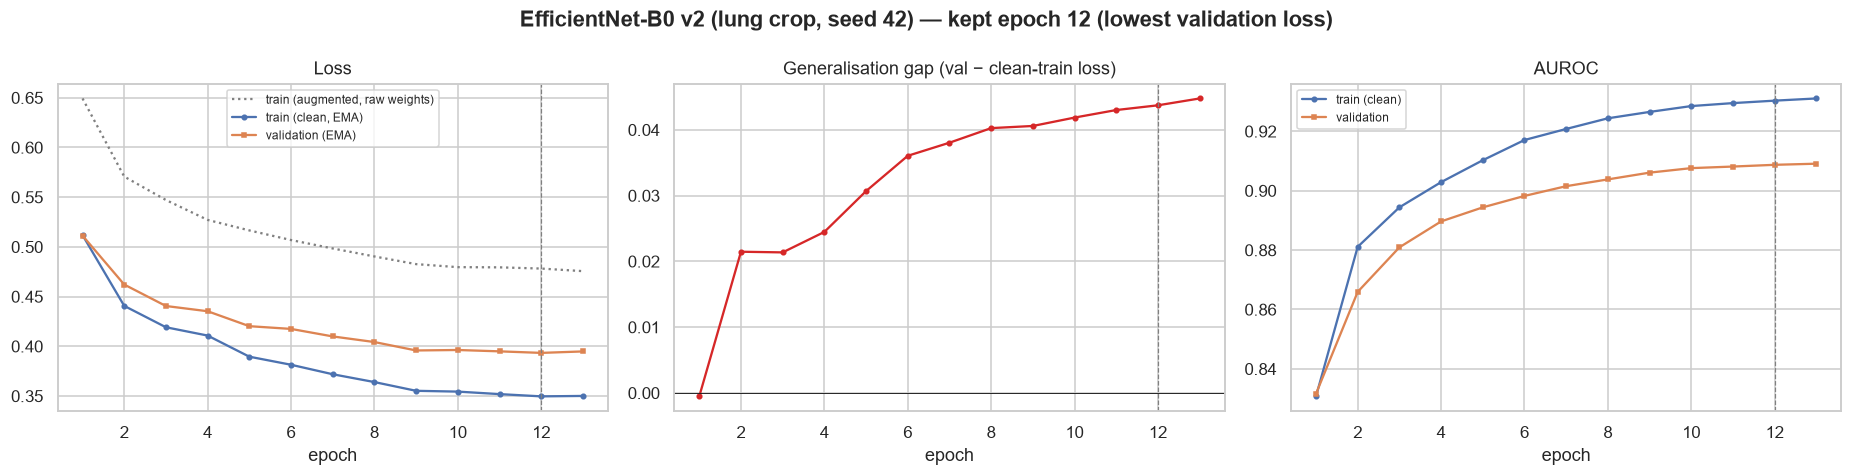

In [8]:
run0 = ROOT / "models" / "efficientnet_b0_v2" / "seed42"
plot_history_v2(histories[42], "EfficientNet-B0 v2 (lung crop, seed 42)")
plt.savefig(run0 / "learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## Seed-to-seed stability

,kept epoch,epochs run,val loss,val AUROC,clean-train AUROC,AUROC gap,minutes
seed,,,,,,,
42,12,13,0.3934,0.9087,0.9303,+0.0216,31
7,12,13,0.3957,0.9050,0.9312,+0.0263,29
2024,13,13,0.3835,0.9119,0.9314,+0.0194,28


Val AUROC across seeds: mean 0.9085, std 0.0035


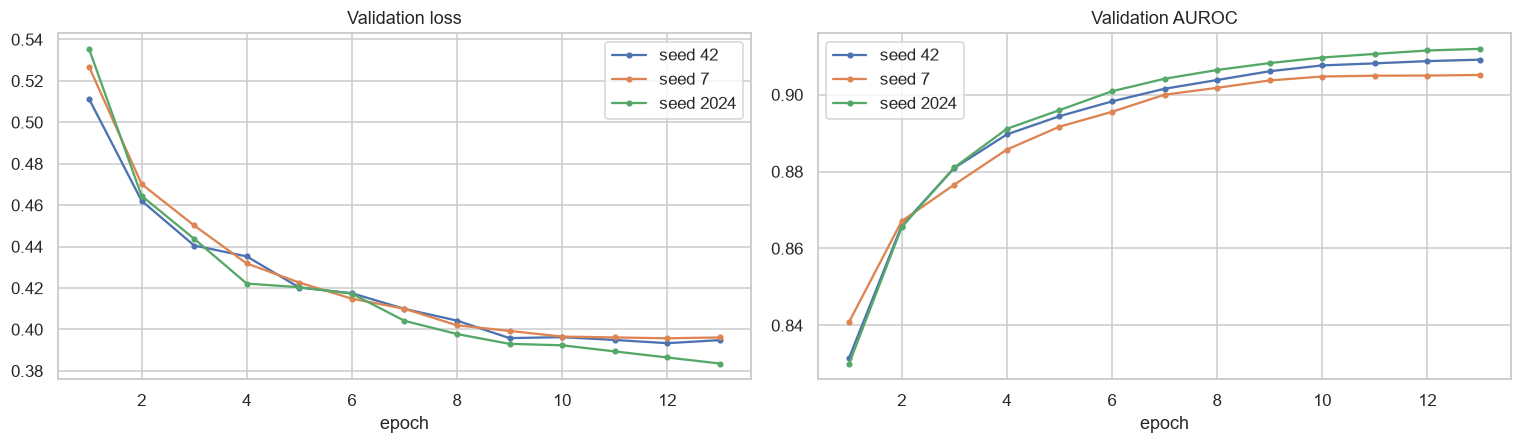

663

In [9]:
rows = []
for seed, hist in histories.items():
    h = pd.DataFrame(hist); b = h.loc[h.val_loss.idxmin()]
    rows.append({"seed": seed, "kept epoch": int(b.epoch), "epochs run": len(h), "val loss": b.val_loss, "val AUROC": b.val_auroc,
                 "clean-train AUROC": b.train_auroc, "AUROC gap": b.train_auroc - b.val_auroc, "minutes": minutes[seed]})
seeds = pd.DataFrame(rows).set_index("seed")
display(seeds.style.format({"val loss": "{:.4f}", "val AUROC": "{:.4f}", "clean-train AUROC": "{:.4f}", "AUROC gap": "{:+.4f}", "minutes": "{:.0f}"}))
print(f"Val AUROC across seeds: mean {seeds['val AUROC'].mean():.4f}, std {seeds['val AUROC'].std():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for seed, hist in histories.items():
    h = pd.DataFrame(hist)
    ax[0].plot(h.epoch, h.val_loss, "o-", ms=3, label=f"seed {seed}"); ax[1].plot(h.epoch, h.val_auroc, "o-", ms=3, label=f"seed {seed}")
ax[0].set(title="Validation loss", xlabel="epoch"); ax[1].set(title="Validation AUROC", xlabel="epoch")
for a in ax: a.legend()
plt.tight_layout(); plt.show()
(ROOT / "models" / "efficientnet_b0_v2" / "seeds_summary.json").write_text(seeds.reset_index().to_json(orient="records", indent=2))